# Détection de la rétinopathie diabétique

**Master TIDE — Deep Learning — Université Paris 1 (cours de J. Rynkiewicz)**

Challenge Kaggle : [diabetic-retinopathy-detection](https://www.kaggle.com/competitions/diabetic-retinopathy-detection)

---

## Le problème

On dispose de photographies du fond de l'œil. Il faut prédire le stade de la rétinopathie
diabétique, une maladie qui abîme progressivement les vaisseaux de la rétine.

| Niveau | Stade |
|:---:|---|
| 0 | Aucune rétinopathie |
| 1 | Légère |
| 2 | Modérée |
| 3 | Sévère |
| 4 | Proliférante |

Deux caractéristiques déterminent toute la suite :

**1. Les classes sont ordonnées.** Le niveau 3 est « entre » 2 et 4. La métrique du challenge,
le *Quadratic Weighted Kappa* (QWK), en tient compte : se tromper de 1 niveau coûte peu, se
tromper de 4 niveaux coûte très cher.

**2. Les classes sont très déséquilibrées.** 73 % des images sont saines, et seulement 2 %
sont au niveau 4.

## La stratégie en trois idées

**Idée 1 — Traiter le problème comme une régression, pas une classification.**
Le réseau produit *un seul nombre* (par exemple 2.7) au lieu de 5 probabilités. On découpe
ensuite ce nombre en niveaux avec 4 seuils. C'est ce qui colle le mieux au QWK : prédire 2.7
quand la vérité est 3 est presque juste, alors qu'une classification traiterait « 2 » et « 3 »
comme deux étiquettes sans rapport.

**Idée 2 — Partir d'un réseau déjà entraîné.** Avec 35 000 images, entraîner de zéro donnerait
un résultat médiocre. On reprend un EfficientNet-B3 pré-entraîné sur ImageNet et on l'adapte.

**Idée 3 — Choisir les seuils plutôt que d'arrondir.** Comme 73 % des images sont saines, le
réseau tire ses prédictions vers le bas. Arrondir à l'entier le plus proche serait sous-optimal :
on cherche les 4 seuils qui maximisent réellement le QWK.

## Avant de lancer

- **Accélérateur** : `Settings > Accelerator > GPU P100`
- **Sources à attacher** (`+ Add Input`) :
  - les données du challenge (`diabetic-retinopathy-detection`)
  - `diabetic-retinopathy-train-unzipped`
  - `diabetic-retinopathy-test-unzipped`

Durée totale attendue : **environ 2 à 3 heures**. Tout est dans ce seul notebook, de la
lecture des données jusqu'au fichier de soumission.

---
# 1. Préparation

In [1]:
import copy
import random
import time

import albumentations as A
import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import timm
import torch
from albumentations.pytorch import ToTensorV2
from scipy.optimize import minimize
from sklearn.metrics import cohen_kappa_score, confusion_matrix
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm

# OpenCV utilise plusieurs threads par défaut. Comme le DataLoader lance déjà plusieurs
# processus en parallèle, on le désactive pour éviter qu'ils se gênent mutuellement.
cv2.setNumThreads(0)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch :", torch.__version__)
print("GPU     :", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "aucun")

PyTorch : 2.1.2
GPU     : Tesla P100-PCIE-16GB


## Les réglages

Tous les paramètres sont regroupés ici. Pour un essai rapide, mettez `NB_IMAGES_TEST` à
5000 : le notebook tourne alors en une dizaine de minutes au lieu de deux heures.

In [2]:
# --- Chemins (fournis par Kaggle une fois les datasets attachés) -----------------
DOSSIER_DONNEES = "/kaggle/input/diabetic-retinopathy-detection"
DOSSIER_TRAIN = "/kaggle/input/diabetic-retinopathy-train-unzipped/train"
DOSSIER_TEST = "/kaggle/input/diabetic-retinopathy-test-unzipped/test"

# --- Images ----------------------------------------------------------------------
TAILLE_IMAGE = 448        # les images seront redimensionnées en 448 x 448

# --- Entraînement ----------------------------------------------------------------
MODELE = "tf_efficientnet_b3.ns_jft_in1k"   # alternatives : "efficientnet_b3", "resnet50"
TAILLE_LOT = 16           # nombre d'images traitées ensemble (réduire si mémoire GPU pleine)
NB_EPOCHS = 5             # nombre de passages sur l'ensemble des images
TAUX_APPRENTISSAGE = 2e-4
NB_WORKERS = 4            # processus qui préparent les images en parallèle

# --- Divers ----------------------------------------------------------------------
GRAINE = 42               # pour que les résultats soient reproductibles
PART_VALIDATION = 0.15    # 15 % des patients servent à évaluer le modèle
NB_IMAGES_TEST = None     # ex. 5000 pour un essai rapide, None pour tout utiliser


def fixer_graine(graine):
    """Fixe le hasard partout pour que deux exécutions donnent le même résultat."""
    random.seed(graine)
    np.random.seed(graine)
    torch.manual_seed(graine)
    torch.cuda.manual_seed_all(graine)


fixer_graine(GRAINE)
torch.backends.cudnn.benchmark = True     # accélère quand la taille d'image est constante

print(f"Images en {TAILLE_IMAGE}x{TAILLE_IMAGE}, lots de {TAILLE_LOT}, {NB_EPOCHS} epochs")

Images en 448x448, lots de 16, 5 epochs


---
# 2. Les données

Le fichier `trainLabels.csv` associe à chaque image son niveau de gravité. Les noms suivent
le format `<patient>_<oeil>`, par exemple `10_left` et `10_right` sont les deux yeux du
patient 10.

In [3]:
donnees = pd.read_csv(f"{DOSSIER_DONNEES}/trainLabels.csv.zip")

# Le numéro avant "_" identifie le patient : on en aura besoin pour découper les données
# proprement (voir section 4).
donnees["patient"] = donnees["image"].str.split("_").str[0]

print(f"{len(donnees):,} images provenant de {donnees['patient'].nunique():,} patients")
donnees.head()

35,126 images provenant de 17,563 patients


,image,level,patient
0,10_left,0,10
1,10_right,0,10
2,13_left,0,13
3,13_right,0,13
4,15_left,1,15


        nombre d'images  pourcentage
niveau                              
0                 25810         73.5
1                  2443          7.0
2                  5292         15.1
3                   873          2.5
4                   708          2.0


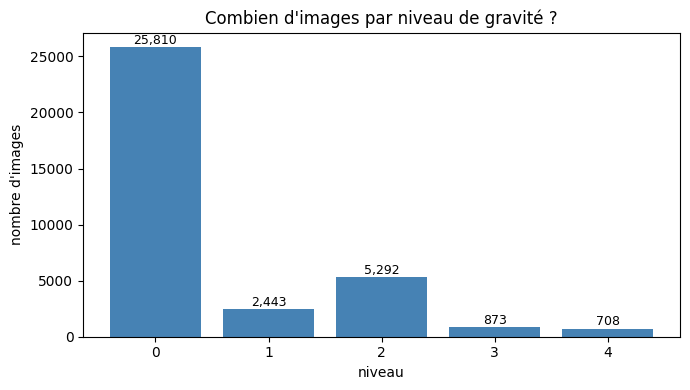

Il y a 36 fois plus d'images saines que d'images de niveau 4.
C'est ce déséquilibre qui justifie la pondération de la section 6.


In [4]:
repartition = donnees["level"].value_counts().sort_index()

tableau = pd.DataFrame({
    "nombre d'images": repartition,
    "pourcentage": (100 * repartition / len(donnees)).round(1),
})
tableau.index.name = "niveau"
print(tableau)

plt.figure(figsize=(7, 4))
plt.bar(repartition.index.astype(str), repartition.values, color="steelblue")
plt.title("Combien d'images par niveau de gravité ?")
plt.xlabel("niveau")
plt.ylabel("nombre d'images")
for i, valeur in enumerate(repartition.values):
    plt.text(i, valeur + 300, f"{valeur:,}", ha="center", fontsize=9)
plt.tight_layout()
plt.show()

print(f"Il y a {repartition.max() / repartition.min():.0f} fois plus d'images saines "
      f"que d'images de niveau {repartition.idxmin()}.")
print("C'est ce déséquilibre qui justifie la pondération de la section 6.")

---
# 3. Préparer une image

Les photos brutes posent trois problèmes :

1. **Elles sont énormes** — jusqu'à 4928 × 3264 pixels, soit 1,3 Mo chacune. Les lire telles
   quelles serait beaucoup trop lent.
2. **Elles sont entourées de noir** — la rétine est un disque au milieu d'un grand cadre noir,
   dont la taille varie selon l'appareil photo.
3. **Elles n'ont pas toutes le même format** — certaines sont plus larges que hautes.

La fonction ci-dessous règle les trois en une fois. L'astuce importante est la première ligne :
`IMREAD_REDUCED_COLOR_4` demande à OpenCV de décoder directement l'image **en quart de
résolution**. C'est environ **4 fois plus rapide** que de tout décoder pour réduire ensuite
(mesuré : 37 ms contre 144 ms par image), et 1188 × 792 pixels restent largement suffisants
pour une cible de 448.

C'est grâce à cette astuce qu'aucun fichier intermédiaire n'est nécessaire : les images sont
préparées à la volée pendant l'entraînement, en parallèle du calcul GPU.

In [5]:
def charger_image(chemin):
    """Lit une photo de fond d'oeil et la renvoie en 448x448, prête pour le réseau.

    Étapes : décodage rapide en quart de résolution, suppression du cadre noir,
    mise au format carré, puis redimensionnement.
    """
    # 1. Décodage direct en quart de résolution (4x plus rapide qu'un décodage complet).
    image = cv2.imread(chemin, cv2.IMREAD_REDUCED_COLOR_4)
    if image is None:
        return None

    # 2. Suppression du cadre noir. On repère les lignes et colonnes suffisamment claires,
    #    puis on découpe l'image sur cette zone. Travailler sur les moyennes de lignes et de
    #    colonnes (plutôt que pixel par pixel) évite qu'un pixel parasite fausse le découpage.
    gris = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    lignes = np.where(gris.mean(axis=1) > 7)[0]
    colonnes = np.where(gris.mean(axis=0) > 7)[0]
    if len(lignes) > 0 and len(colonnes) > 0:
        image = image[lignes[0]:lignes[-1] + 1, colonnes[0]:colonnes[-1] + 1]

    # 3. Mise au format carré en ajoutant du noir sur les côtés les plus courts.
    #    On complète plutôt que d'étirer, pour ne pas déformer la rétine.
    hauteur, largeur = image.shape[:2]
    cote = max(hauteur, largeur)
    haut = (cote - hauteur) // 2
    gauche = (cote - largeur) // 2
    image = cv2.copyMakeBorder(image, haut, cote - hauteur - haut,
                               gauche, cote - largeur - gauche,
                               cv2.BORDER_CONSTANT, value=(0, 0, 0))

    # 4. Redimensionnement final. INTER_AREA moyenne les pixels : c'est le bon choix pour
    #    réduire une image sans créer d'artefacts.
    image = cv2.resize(image, (TAILLE_IMAGE, TAILLE_IMAGE), interpolation=cv2.INTER_AREA)

    # OpenCV travaille en BGR, tout le reste (matplotlib, PyTorch) attend du RGB.
    return cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

### Vérification visuelle

On regarde une image de chaque niveau, avant et après traitement. Le pourcentage indique la
part de l'image réellement occupée par la rétine.

Il augmente nettement pour les photos entourées d'un large cadre noir (typiquement de 47 % à
80 %). Sur les photos déjà cadrées serré — celles où la rétine est coupée en haut et en bas —
il peut rester stable : le recadrage ne trouve presque rien à retirer sur les côtés, tandis que
la mise au carré rajoute des bandes noires. C'est normal, et sans conséquence : ce qui compte
est que la rétine occupe une part homogène d'une image à l'autre.

In [6]:
exemples = donnees.sort_values("level").groupby("level").head(1)

figure, axes = plt.subplots(2, len(exemples), figsize=(3.2 * len(exemples), 7))

for colonne, (_, ligne) in enumerate(exemples.iterrows()):
    chemin = f"{DOSSIER_TRAIN}/{ligne['image']}.jpeg"

    brute = cv2.cvtColor(cv2.imread(chemin, cv2.IMREAD_REDUCED_COLOR_4), cv2.COLOR_BGR2RGB)
    traitee = charger_image(chemin)

    def part_utile(img):
        return (cv2.cvtColor(img, cv2.COLOR_RGB2GRAY) > 7).mean()

    axes[0, colonne].imshow(brute)
    axes[0, colonne].set_title(f"niveau {ligne['level']} — avant\n"
                               f"{brute.shape[1]}x{brute.shape[0]}, "
                               f"rétine {part_utile(brute):.0%}", fontsize=9)
    axes[1, colonne].imshow(traitee)
    axes[1, colonne].set_title(f"après\n{TAILLE_IMAGE}x{TAILLE_IMAGE}, "
                               f"rétine {part_utile(traitee):.0%}", fontsize=9)
    axes[0, colonne].axis("off")
    axes[1, colonne].axis("off")

plt.tight_layout()
plt.show()

---
# 4. Séparer entraînement et validation

Il faut mettre de côté des images pour mesurer honnêtement la qualité du modèle.

**Le piège à éviter :** chaque patient a deux yeux, et ses deux images se ressemblent beaucoup.
Si l'œil gauche va dans l'entraînement et l'œil droit dans la validation, le modèle aura déjà
« presque vu » l'image de validation. Le score paraîtrait excellent et serait faux.

**La solution :** tirer au sort des **patients**, pas des images. Les deux yeux d'un même
patient restent toujours du même côté.

In [7]:
# On mélange la liste des patients, puis on en réserve 15 % pour la validation.
patients = donnees["patient"].unique()
melange = np.random.default_rng(GRAINE).permutation(patients)
patients_validation = set(melange[:int(PART_VALIDATION * len(melange))])

donnees["validation"] = donnees["patient"].isin(patients_validation)

entrainement = donnees[~donnees["validation"]].reset_index(drop=True)
validation = donnees[donnees["validation"]].reset_index(drop=True)

print(f"Entraînement : {len(entrainement):,} images ({entrainement['patient'].nunique():,} patients)")
print(f"Validation   : {len(validation):,} images ({validation['patient'].nunique():,} patients)")

# Vérification : aucun patient ne doit apparaître des deux côtés.
communs = set(entrainement["patient"]) & set(validation["patient"])
print(f"\nPatients présents des deux côtés : {len(communs)} (doit être 0)")

# Vérification : les deux ensembles doivent avoir des proportions de niveaux comparables.
comparaison = pd.DataFrame({
    "entraînement (%)": (100 * entrainement["level"].value_counts(normalize=True)).round(1),
    "validation (%)": (100 * validation["level"].value_counts(normalize=True)).round(1),
}).sort_index()
comparaison.index.name = "niveau"
print(comparaison)

Entraînement : 29,858 images (14,929 patients)
Validation   : 5,268 images (2,634 patients)
Patients présents des deux côtés : 0 (doit être 0)
        entraînement (%)  validation (%)
niveau                                  
0                   73.4            73.7
1                    7.0             6.6
2                   15.1            15.1
3                    2.5             2.4
4                    2.0             2.1


---
# 5. Alimenter le réseau

Un `Dataset` explique à PyTorch comment obtenir une image. Il est appelé en parallèle par
plusieurs processus pendant que le GPU calcule, ce qui masque le temps de lecture.

**Les augmentations** modifient légèrement chaque image à chaque passage (retournements,
rotations, variations de luminosité). Le réseau ne voit ainsi jamais deux fois exactement la
même chose, ce qui l'empêche d'apprendre les images par cœur.

Une particularité utile ici : un fond d'œil est presque circulaire et n'a pas de « haut » ni de
« bas » naturel. On peut donc le retourner et le faire pivoter librement, ce qui serait absurde
sur des photos ordinaires. On reste toutefois mesuré : les lésions à repérer ne font parfois que
quelques pixels, et une déformation trop forte les effacerait.

In [8]:
# Valeurs de normalisation d'ImageNet : le modèle pré-entraîné les attend.
MOYENNE_IMAGENET = (0.485, 0.456, 0.406)
ECART_IMAGENET = (0.229, 0.224, 0.225)

augmentations_entrainement = A.Compose([
    A.HorizontalFlip(p=0.5),                       # miroir gauche-droite
    A.VerticalFlip(p=0.5),                         # miroir haut-bas
    A.Affine(scale=(0.9, 1.1), rotate=(-180, 180), p=0.7),   # zoom et rotation légers
    A.RandomBrightnessContrast(0.15, 0.15, p=0.5),  # les appareils photo varient beaucoup
    A.Normalize(MOYENNE_IMAGENET, ECART_IMAGENET),
    ToTensorV2(),
])

# En validation et en test : aucune modification aléatoire, on veut un résultat stable.
augmentations_evaluation = A.Compose([
    A.Normalize(MOYENNE_IMAGENET, ECART_IMAGENET),
    ToTensorV2(),
])

In [9]:
class ImagesRetine(Dataset):
    """Fournit les images une par une à PyTorch.

    `poids` sert à compenser le déséquilibre des classes (voir section 6). Pour le jeu de
    test, il n'y a pas d'étiquette : on renvoie alors seulement l'image.
    """

    def __init__(self, table, dossier, augmentations, poids=None, avec_etiquette=True):
        self.noms = table["image"].tolist()
        self.niveaux = table["level"].tolist() if avec_etiquette else None
        self.dossier = dossier
        self.augmentations = augmentations
        self.poids = poids
        self.avec_etiquette = avec_etiquette

    def __len__(self):
        return len(self.noms)

    def __getitem__(self, i):
        image = charger_image(f"{self.dossier}/{self.noms[i]}.jpeg")

        # Si une image est illisible, on renvoie une image noire plutôt que d'interrompre
        # un entraînement de plusieurs heures.
        if image is None:
            image = np.zeros((TAILLE_IMAGE, TAILLE_IMAGE, 3), dtype=np.uint8)

        image = self.augmentations(image=image)["image"]

        if not self.avec_etiquette:
            return image

        niveau = self.niveaux[i]
        poids = 1.0 if self.poids is None else self.poids[niveau]
        # Le niveau est un nombre à virgule car on fait une régression, pas une classification.
        return image, torch.tensor(float(niveau)), torch.tensor(float(poids))

---
# 6. Compenser le déséquilibre

Sans précaution, le réseau découvrirait vite qu'annoncer « niveau 0 » pour tout le monde lui
donne 73 % de bonnes réponses — et n'apprendrait rien des cas graves, qui sont pourtant les
plus importants à détecter.

On donne donc **plus de poids aux erreurs sur les niveaux rares**. Plutôt que d'utiliser
l'inverse de la fréquence (trop brutal : le niveau 4 pèserait 36 fois le niveau 0), on prend sa
**racine carrée**, ce qui adoucit la correction tout en la gardant efficace.

In [10]:
frequences = entrainement["level"].value_counts(normalize=True).sort_index()

poids_bruts = (1 / frequences) ** 0.5          # racine carrée = correction adoucie
poids_classes = (poids_bruts / (poids_bruts * frequences).sum()).to_dict()

for niveau in range(5):
    print(f"niveau {niveau} : {100 * frequences[niveau]:5.1f} % des images "
          f"-> poids {poids_classes[niveau]:.2f}")

print(f"\nLe niveau le plus rare compte {max(poids_classes.values()) / min(poids_classes.values()):.1f} "
      f"fois plus que le plus fréquent.")

niveau 0 :  73.4 % des images -> poids 0.65
niveau 1 :   7.0 % des images -> poids 2.09
niveau 2 :  15.1 % des images -> poids 1.42
niveau 3 :   2.5 % des images -> poids 3.50
niveau 4 :   2.0 % des images -> poids 3.91
Le niveau le plus rare compte 6.1 fois plus que le plus fréquent.


In [11]:
donnees_entrainement = ImagesRetine(entrainement, DOSSIER_TRAIN,
                                    augmentations_entrainement, poids_classes)
donnees_validation = ImagesRetine(validation, DOSSIER_TRAIN,
                                  augmentations_evaluation, poids_classes)

chargeur_entrainement = DataLoader(donnees_entrainement, batch_size=TAILLE_LOT, shuffle=True,
                                   num_workers=NB_WORKERS, pin_memory=True, drop_last=True)
chargeur_validation = DataLoader(donnees_validation, batch_size=TAILLE_LOT * 2, shuffle=False,
                                 num_workers=NB_WORKERS, pin_memory=True)

# Contrôle : on affiche un lot après augmentation.
images, niveaux, poids = next(iter(chargeur_entrainement))
print(f"Un lot contient {images.shape[0]} images de taille {tuple(images.shape[1:])}")
print(f"Niveaux : {[int(n) for n in niveaux[:8]]}")

# On annule la normalisation pour pouvoir afficher les images.
apercu = images[:4].permute(0, 2, 3, 1).numpy() * np.array(ECART_IMAGENET) + np.array(MOYENNE_IMAGENET)
figure, axes = plt.subplots(1, 4, figsize=(13, 3.5))
for axe, image, niveau in zip(axes, apercu, niveaux[:4]):
    axe.imshow(np.clip(image, 0, 1))
    axe.set_title(f"niveau {int(niveau)}")
    axe.axis("off")
plt.suptitle("Exemples après augmentation aléatoire")
plt.tight_layout()
plt.show()

Un lot contient 16 images de taille (3, 448, 448)
Niveaux : [0, 0, 0, 2, 4, 2, 0, 0]


---
# 7. Le modèle

On part d'un **EfficientNet-B3** déjà entraîné sur ImageNet. Il a appris à reconnaître formes,
textures et contours sur des millions de photos ; ces compétences se transposent bien aux
images médicales. On remplace simplement sa dernière couche par une couche à **une seule
sortie** : le nombre qui représente le stade de la maladie.

Pourquoi EfficientNet-B3 plutôt qu'un modèle plus gros ? Il offre le meilleur rapport
précision / vitesse pour ce cas : assez rapide pour que le GPU suive le rythme de lecture des
images, et assez puissant pour bien classer. Un modèle deux fois plus lourd passerait
l'essentiel de son temps à attendre les images.

In [12]:
modele = timm.create_model(
    MODELE,
    pretrained=True,      # on récupère les poids appris sur ImageNet
    num_classes=1,        # une seule sortie : la régression
    drop_rate=0.3,        # dropout : évite d'apprendre les images par coeur
).to(DEVICE)

nb_parametres = sum(p.numel() for p in modele.parameters())
print(f"{MODELE}")
print(f"{nb_parametres / 1e6:.1f} millions de paramètres")

# Vérification : deux images en entrée doivent donner deux nombres en sortie.
with torch.no_grad():
    essai = torch.zeros(2, 3, TAILLE_IMAGE, TAILLE_IMAGE, device=DEVICE)
    print(f"Entrée {tuple(essai.shape)} -> sortie {tuple(modele(essai).shape)}")

tf_efficientnet_b3.ns_jft_in1k
10.7 millions de paramètres
Entrée (2, 3, 448, 448) -> sortie (2, 1)


---
# 8. Mesurer l'erreur et la qualité

**La fonction de coût** est l'écart quadratique moyen, pondéré par l'importance de chaque
classe. On pénalise le carré de l'erreur, exactement comme le fait le QWK — les deux sont donc
alignés.

**La métrique** est le QWK. Deux repères pour la lire : 0 correspond à un modèle qui répond au
hasard, 1 à un modèle parfait. Sur ce challenge, un bon score se situe autour de 0,70 – 0,80.

In [13]:
def cout(predictions, cibles, poids):
    """Écart quadratique moyen, pondéré par l'importance de chaque classe."""
    return (poids * (predictions - cibles) ** 2).sum() / poids.sum()


def score_qwk(vrais_niveaux, niveaux_predits):
    """Quadratic Weighted Kappa : la métrique officielle du challenge."""
    return cohen_kappa_score(vrais_niveaux, niveaux_predits, weights="quadratic")


def decouper(valeurs, seuils):
    """Transforme les nombres produits par le réseau en niveaux 0 à 4.

    Exemple : avec les seuils [0.5, 1.5, 2.5, 3.5], la valeur 2.7 devient le niveau 3.
    """
    return np.digitize(valeurs, np.sort(seuils))

---
# 9. Entraînement

Deux fonctions : une qui fait apprendre le modèle sur un passage complet des données, une qui
l'évalue sans rien modifier.

Deux détails techniques qui font gagner du temps sans rien changer au résultat :

- **`autocast`** fait calculer le réseau en demi-précision (16 bits au lieu de 32). Cela divise
  par deux la mémoire utilisée et double environ la vitesse.
- **`GradScaler`** accompagne le point précédent : en 16 bits, les très petites valeurs seraient
  arrondies à zéro, ce qui bloquerait l'apprentissage. Il les met temporairement à l'échelle
  pour l'éviter.

In [14]:
def entrainer_une_epoch(modele, chargeur, optimiseur, planificateur, amplificateur):
    """Fait passer toutes les images une fois et ajuste les poids du réseau."""
    modele.train()
    somme_cout, nb_images = 0.0, 0

    barre = tqdm(chargeur, desc="entraînement", leave=False)
    for images, niveaux, poids in barre:
        images = images.to(DEVICE, non_blocking=True)
        niveaux = niveaux.to(DEVICE, non_blocking=True)
        poids = poids.to(DEVICE, non_blocking=True)

        optimiseur.zero_grad(set_to_none=True)

        with torch.autocast("cuda", dtype=torch.float16, enabled=DEVICE == "cuda"):
            predictions = modele(images).squeeze(1)
            valeur_cout = cout(predictions, niveaux, poids)

        amplificateur.scale(valeur_cout).backward()   # calcule les gradients
        amplificateur.step(optimiseur)                # met à jour les poids
        amplificateur.update()
        planificateur.step()                          # ajuste le taux d'apprentissage

        somme_cout += valeur_cout.item() * len(images)
        nb_images += len(images)
        barre.set_postfix(cout=f"{somme_cout / nb_images:.4f}")

    return somme_cout / nb_images


@torch.no_grad()
def evaluer(modele, chargeur):
    """Applique le modèle sans modifier ses poids. Renvoie le coût, les prédictions et les vrais niveaux."""
    modele.eval()
    somme_cout, nb_images = 0.0, 0
    predictions, cibles = [], []

    for images, niveaux, poids in tqdm(chargeur, desc="validation", leave=False):
        images = images.to(DEVICE, non_blocking=True)

        with torch.autocast("cuda", dtype=torch.float16, enabled=DEVICE == "cuda"):
            sortie = modele(images).squeeze(1)

        sortie = sortie.float().cpu()
        somme_cout += cout(sortie, niveaux, poids).item() * len(images)
        nb_images += len(images)
        predictions.append(sortie.numpy())
        cibles.append(niveaux.numpy())

    return somme_cout / nb_images, np.concatenate(predictions), np.concatenate(cibles)

`OneCycleLR` fait monter le taux d'apprentissage au début (pour ne pas abîmer d'emblée les
connaissances issues d'ImageNet), puis le fait redescendre progressivement afin d'affiner la
solution en fin d'entraînement.

In [17]:
optimiseur = torch.optim.AdamW(modele.parameters(), lr=TAUX_APPRENTISSAGE, weight_decay=1e-2)

planificateur = torch.optim.lr_scheduler.OneCycleLR(
    optimiseur,
    max_lr=TAUX_APPRENTISSAGE,
    total_steps=NB_EPOCHS * len(chargeur_entrainement),
    pct_start=0.1,        # 10 % du temps en montée, 90 % en descente
)

#amplificateur = torch.amp.GradScaler("cuda", enabled=DEVICE == "cuda")
amplificateur = torch.cuda.amp.GradScaler(enabled=DEVICE == "cuda")

print(f"{len(chargeur_entrainement)} lots par epoch, "
      f"{NB_EPOCHS * len(chargeur_entrainement)} mises à jour au total")

1866 lots par epoch, 9330 mises à jour au total


On garde en mémoire la version du modèle qui obtient le meilleur QWK, et pas simplement la
dernière : le score peut se dégrader sur les derniers passages.

Compter environ **15 à 25 minutes par epoch**.

In [ ]:
historique = []
meilleur_score = -1
meilleurs_poids = None

for epoch in range(1, NB_EPOCHS + 1):
    depart = time.time()

    cout_entrainement = entrainer_une_epoch(modele, chargeur_entrainement, optimiseur,
                                            planificateur, amplificateur)
    cout_validation, predictions, cibles = evaluer(modele, chargeur_validation)

    # Score obtenu en arrondissant simplement (les seuils seront optimisés en section 10).
    score = score_qwk(cibles, np.clip(np.round(predictions), 0, 4))

    duree = (time.time() - depart) / 60
    historique.append({"epoch": epoch, "coût entraînement": cout_entrainement,
                       "coût validation": cout_validation, "QWK": score, "minutes": duree})

    marque = ""
    if score > meilleur_score:
        meilleur_score = score
        # copie profonde : sinon on garderait une référence qui changerait à l'epoch suivante
        meilleurs_poids = copy.deepcopy(modele.state_dict())
        marque = "  <- meilleur"

    print(f"epoch {epoch}/{NB_EPOCHS} | coût {cout_entrainement:.4f} / {cout_validation:.4f} "
          f"| QWK {score:.4f} | {duree:.1f} min{marque}")

# On repart du meilleur état pour la suite.
modele.load_state_dict(meilleurs_poids)
print(f"\nMeilleur QWK en validation : {meilleur_score:.4f}")

epoch 1/5 | coût 3.6869 / 0.7902 | QWK 0.5599 | 15.6 min  <- meilleur


epoch 2/5 | coût 0.9089 / 0.6215 | QWK 0.6818 | 15.9 min  <- meilleur


epoch 3/5 | coût 0.7171 / 0.5467 | QWK 0.7156 | 14.8 min  <- meilleur


,epoch,coût entraînement,coût validation,QWK,minutes
0,1,3.6869,0.7902,0.5599,15.6317
1,2,0.9089,0.6215,0.6818,15.8587
2,3,0.7171,0.5467,0.7156,14.7917
3,4,0.6031,0.5243,0.7104,15.5952
4,5,0.5169,0.4868,0.7705,14.9281


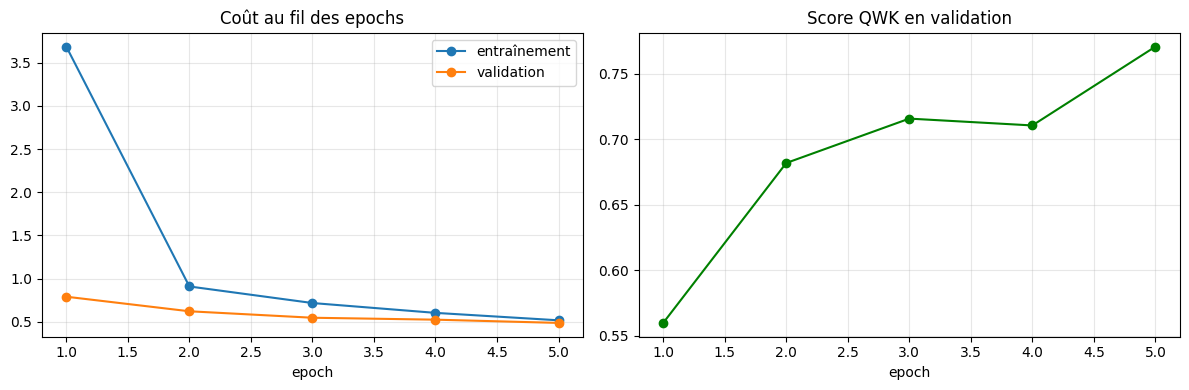

In [19]:
suivi = pd.DataFrame(historique)
display(suivi.round(4))

figure, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(suivi["epoch"], suivi["coût entraînement"], "o-", label="entraînement")
axes[0].plot(suivi["epoch"], suivi["coût validation"], "o-", label="validation")
axes[0].set_title("Coût au fil des epochs")
axes[0].set_xlabel("epoch")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(suivi["epoch"], suivi["QWK"], "o-", color="green")
axes[1].set_title("Score QWK en validation")
axes[1].set_xlabel("epoch")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

---
# 10. Choisir les seuils

Le réseau produit des nombres continus. Il reste à décider à partir de quelle valeur on bascule
d'un niveau au suivant.

Arrondir (seuils 0,5 / 1,5 / 2,5 / 3,5) semble naturel mais fonctionne mal ici : comme 73 % des
images sont saines, le réseau tire ses prédictions vers le bas et hésite rarement au-delà de 2.
On cherche donc les 4 seuils qui **maximisent directement le QWK** sur la validation.

Le QWK varie par paliers en fonction des seuils, il n'est donc pas dérivable : on utilise
Nelder-Mead, une méthode de recherche qui n'a pas besoin de dérivées.

In [20]:
def qualite_des_seuils(seuils, valeurs, vrais_niveaux):
    """Renvoie l'opposé du QWK, car la fonction `minimize` cherche un minimum."""
    return -score_qwk(vrais_niveaux, decouper(valeurs, seuils))


_, predictions_validation, cibles_validation = evaluer(modele, chargeur_validation)

seuils_par_defaut = [0.5, 1.5, 2.5, 3.5]
resultat = minimize(qualite_des_seuils, seuils_par_defaut,
                    args=(predictions_validation, cibles_validation),
                    method="nelder-mead")
seuils = np.sort(resultat.x)

score_arrondi = score_qwk(cibles_validation, np.clip(np.round(predictions_validation), 0, 4))
score_optimise = score_qwk(cibles_validation, decouper(predictions_validation, seuils))

print(f"QWK en arrondissant      : {score_arrondi:.4f}")
print(f"QWK avec seuils optimisés : {score_optimise:.4f}   (gain +{score_optimise - score_arrondi:.4f})")
print(f"\nSeuils retenus : {np.round(seuils, 3).tolist()}")

QWK en arrondissant      : 0.7705
QWK avec seuils optimisés : 0.8002   (gain +0.0297)
Seuils retenus : [0.706, 1.281, 2.041, 2.939]


### Où le modèle se trompe-t-il ?

La matrice de confusion croise le vrai niveau (en ligne) et le niveau prédit (en colonne). Une
bonne matrice concentre ses valeurs sur la diagonale. Les erreurs proches de la diagonale sont
peu pénalisées par le QWK, contrairement à celles des coins.

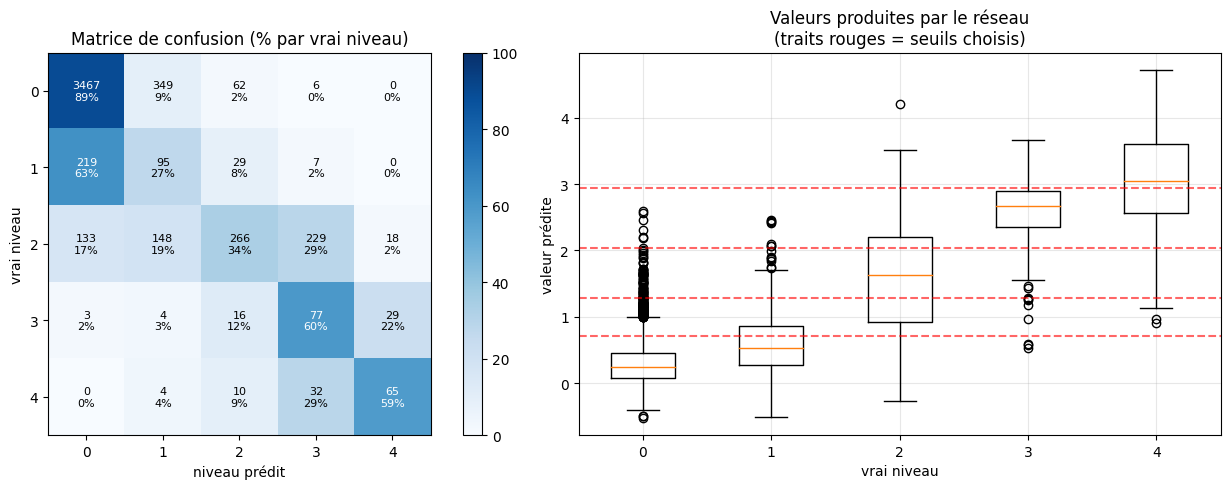

Exactitude : 75.4%


In [21]:
niveaux_predits = decouper(predictions_validation, seuils)
matrice = confusion_matrix(cibles_validation.astype(int), niveaux_predits, labels=range(5))
matrice_pct = 100 * matrice / matrice.sum(axis=1, keepdims=True).clip(min=1)

figure, axes = plt.subplots(1, 2, figsize=(14, 5))

image = axes[0].imshow(matrice_pct, cmap="Blues", vmin=0, vmax=100)
axes[0].set_title("Matrice de confusion (% par vrai niveau)")
axes[0].set_xlabel("niveau prédit")
axes[0].set_ylabel("vrai niveau")
axes[0].set_xticks(range(5))
axes[0].set_yticks(range(5))
for i in range(5):
    for j in range(5):
        axes[0].text(j, i, f"{matrice[i, j]}\n{matrice_pct[i, j]:.0f}%", ha="center",
                     va="center", fontsize=8,
                     color="white" if matrice_pct[i, j] > 50 else "black")
plt.colorbar(image, ax=axes[0], fraction=0.046)

axes[1].boxplot([predictions_validation[cibles_validation == n] for n in range(5)],
                positions=range(5))
for seuil in seuils:
    axes[1].axhline(seuil, color="red", linestyle="--", alpha=0.6)
axes[1].set_title("Valeurs produites par le réseau\n(traits rouges = seuils choisis)")
axes[1].set_xlabel("vrai niveau")
axes[1].set_ylabel("valeur prédite")
axes[1].set_xticks(range(5))
axes[1].set_xticklabels(range(5))
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Exactitude : {(niveaux_predits == cibles_validation).mean():.1%}")

---
# 11. Prédire sur les images de test

Le fichier `sampleSubmission.csv` donne la liste exacte des images attendues, dans l'ordre
attendu. On s'appuie dessus plutôt que de lister le dossier, pour être certain de ne rien
oublier ni intervertir.

On applique aussi une **augmentation au moment du test** : chaque image est vue à l'endroit
puis en miroir, et on garde la moyenne des deux prédictions. Cela stabilise le résultat, et ne
coûte presque rien puisque le temps est dominé par la lecture des images, pas par le calcul.

In [22]:
soumission = pd.read_csv(f"{DOSSIER_DONNEES}/sampleSubmission.csv.zip")

if NB_IMAGES_TEST is not None:                 # mode essai rapide
    soumission = soumission.head(NB_IMAGES_TEST).copy()

print(f"{len(soumission):,} images à prédire")
soumission.head()

53,576 images à prédire


,image,level
0,1_left,0
1,1_right,0
2,2_left,0
3,2_right,0
4,3_left,0


In [23]:
donnees_test = ImagesRetine(soumission, DOSSIER_TEST, augmentations_evaluation,
                            avec_etiquette=False)
chargeur_test = DataLoader(donnees_test, batch_size=TAILLE_LOT * 2, shuffle=False,
                           num_workers=NB_WORKERS, pin_memory=True)

modele.eval()
predictions_test = []
depart = time.time()

with torch.no_grad():
    for images in tqdm(chargeur_test, desc="prédiction"):
        images = images.to(DEVICE, non_blocking=True)

        with torch.autocast("cuda", dtype=torch.float16, enabled=DEVICE == "cuda"):
            normale = modele(images).squeeze(1)
            miroir = modele(torch.flip(images, dims=[3])).squeeze(1)   # image retournée
            moyenne = (normale + miroir) / 2

        predictions_test.append(moyenne.float().cpu().numpy())

predictions_test = np.concatenate(predictions_test)
print(f"\nTerminé en {(time.time() - depart) / 60:.1f} min")
print(f"Valeurs prédites : de {predictions_test.min():.2f} à {predictions_test.max():.2f}")

Terminé en 24.1 min
Valeurs prédites : de -0.85 à 6.23


### Contrôle avant soumission

On compare la répartition prédite à celle observée à l'entraînement. Elles n'ont aucune raison
d'être identiques, mais un écart important signalerait un problème (seuils mal choisis, modèle
insuffisamment entraîné).

        test prédit (%)  entraînement (%)
niveau                                   
0                  73.1              73.4
1                  11.3               7.0
2                   6.4              15.1
3                   6.9               2.5
4                   2.2               2.0


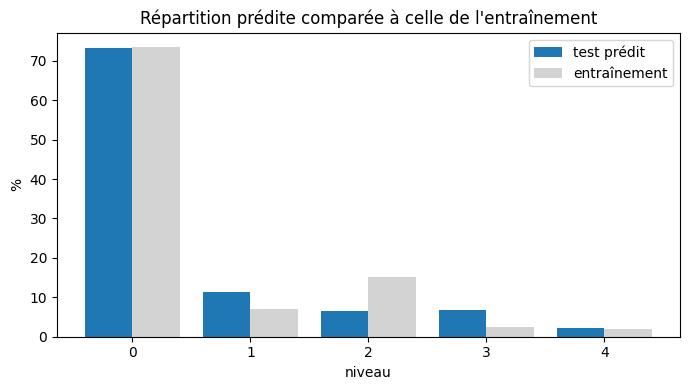

In [24]:
soumission["level"] = np.clip(decouper(predictions_test, seuils), 0, 4).astype(int)

repartition_predite = soumission["level"].value_counts(normalize=True).sort_index()
comparaison = pd.DataFrame({
    "test prédit (%)": (100 * repartition_predite).round(1),
    "entraînement (%)": (100 * frequences).round(1),
}).fillna(0)
comparaison.index.name = "niveau"
print(comparaison)

plt.figure(figsize=(7, 4))
positions = np.arange(5)
plt.bar(positions - 0.2, comparaison["test prédit (%)"], width=0.4, label="test prédit")
plt.bar(positions + 0.2, comparaison["entraînement (%)"], width=0.4, label="entraînement",
        color="lightgrey")
plt.xticks(positions)
plt.xlabel("niveau")
plt.ylabel("%")
plt.title("Répartition prédite comparée à celle de l'entraînement")
plt.legend()
plt.tight_layout()
plt.show()

In [25]:
soumission.to_csv("submission.csv", index=False)

# Vérifications finales : mieux vaut détecter une erreur ici qu'après une soumission ratée.
verification = pd.read_csv("submission.csv")
reference = pd.read_csv(f"{DOSSIER_DONNEES}/sampleSubmission.csv.zip")

assert list(verification.columns) == ["image", "level"], "les colonnes doivent être image, level"
assert verification["level"].between(0, 4).all(), "les niveaux doivent aller de 0 à 4"
assert not verification.isna().any().any(), "il ne doit rester aucune valeur manquante"
if NB_IMAGES_TEST is None:
    assert len(verification) == len(reference), "il manque des lignes"
    assert verification["image"].tolist() == reference["image"].tolist(), "l'ordre a changé"
    print("Fichier complet et conforme.")
else:
    print(f"ATTENTION : essai partiel ({len(verification):,} lignes). "
          "Remettre NB_IMAGES_TEST à None pour une soumission valide.")

print(f"\nsubmission.csv : {len(verification):,} lignes")
print(verification.head())

# On sauvegarde aussi le modèle, au cas où il servirait plus tard.
torch.save({"poids": meilleurs_poids, "seuils": seuils.tolist(), "modele": MODELE},
           "modele_retinopathie.pth")
print("\nModèle sauvegardé dans modele_retinopathie.pth")

Fichier complet et conforme.
submission.csv : 53,576 lignes
     image  level
0   1_left      0
1  1_right      0
2   2_left      0
3  2_right      0
4   3_left      3
Modèle sauvegardé dans modele_retinopathie.pth


---
# 12. Bilan

## Ce qui a été fait

| Étape | Choix retenu | Pourquoi |
|---|---|---|
| Lecture des images | Décodage en quart de résolution | 4× plus rapide, aucun fichier intermédiaire |
| Cadrage | Suppression du cadre noir | La rétine occupe une part constante de l'image |
| Découpage des données | Par patient | Évite que les deux yeux d'un patient soient séparés |
| Type de problème | Régression | Respecte l'ordre des niveaux, comme le QWK |
| Modèle | EfficientNet-B3 pré-entraîné | Bon compromis précision / vitesse |
| Déséquilibre | Pondération en racine carrée | Corrige sans déstabiliser |
| Décision finale | Seuils optimisés | Gain direct de QWK sur un simple arrondi |

## Soumettre

1. **Save Version** → *Save & Run All (Commit)*, puis attendre la fin.
2. Onglet **Output** → *Submit to Competition*. La compétition étant fermée depuis 2015, il
   s'agit d'une *late submission* : le score s'affiche normalement.
3. Le score **Private** (calculé sur environ 80 % des images) est celui qui fait référence.

## Repères de score

| | QWK |
|---|---|
| Vainqueur 2015 | 0,849 |
| ~10ᵉ place | ≈ 0,79 |
| ~50ᵉ place | ≈ 0,70 |
| Médiane des 661 équipes | ≈ 0,40 |
| Tout prédire à 0 | 0,000 |

## Pour aller plus loin

Par rapport gain / effort décroissant :

1. **Augmenter le nombre d'epochs** (8 à 10 au lieu de 5) — le plus simple, souvent efficace.
2. **Monter la résolution** à 512 px — les micro-anévrismes qui distinguent les niveaux 1, 2 et
   3 mesurent quelques pixels seulement.
3. **Utiliser un modèle plus gros** (`tf_efficientnet_b4.ns_jft_in1k`) — plus lent, un peu plus
   précis.
4. **Entraîner plusieurs modèles et moyenner leurs prédictions** — c'est ce que faisaient les
   équipes du haut du classement, mais le coût est multiplié d'autant.
5. **Exploiter les deux yeux d'un même patient** — leurs niveaux coïncident dans une large
   majorité des cas, ce qui constitue une information encore inutilisée ici.